# GSE149282

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-11-01
> - Modified: 2026-04-11

# 1. Experimental Design

> Genome-wide open chromatin methylome profiles in colorectal cancer
> - Homo sapiens
> - GPL21145: Illumina Infinium MethylationEPIC BeadChip
> - Universiti Kebangsaan Malaysia
> - Ishak M, Baharudin R, Mohamed Rose I, Sagap I, Mazlan L, Mohd Azman ZA, Abu N, Jamal R, Lee L-H, Ab Mutalib NS. Genome-Wide Open Chromatin Methylome Profiles in Colorectal Cancer. Biomolecules. 2020; 10(5):719. https://doi.org/10.3390/biom10050719

| Sample | Tissue | Replicate |
| - | - | - |
| Normal | Colon adjacent normal | rep1~12 |
| Cancer | Colon cancer tissue | rep1~12 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(minfi))
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(DMRcate))
suppressPackageStartupMessages(library(IlluminaHumanMethylationEPICmanifest))
suppressPackageStartupMessages(library(IlluminaHumanMethylationEPICanno.ilm10b4.hg19))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 2. Download Data

In [2]:
suppressPackageStartupMessages(library(GEOquery))

In [3]:
gse_id <- "GSE149282"
data_dir <- file.path("~/dataset_1/methylation_dataset/array", gse_id)
dir.create(data_dir, showWarnings = FALSE)

In [ ]:
getGEOSuppFiles(GEO = gse_id, makeDirectory = FALSE, baseDir = data_dir)

,size,isdir,mode,mtime,ctime,atime,uid,gid,uname,grname,fname,destdir,filepath,GEO
,<dbl>,<lgl>,<octmode>,<dttm>,<dttm>,<dttm>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
~/dataset_1/methylation_dataset/array/GSE149282/GSE149282_RAW.tar,528158720,FALSE,777,2026-04-11 10:15:16,2026-04-11 10:15:16,2026-04-11 10:15:16,1000,1000,fugui,fugui,GSE149282_RAW.tar,~/dataset_1/methylation_dataset/array/GSE149282,~/dataset_1/methylation_dataset/array/GSE149282/GSE149282_RAW.tar,GSE149282
~/dataset_1/methylation_dataset/array/GSE149282/GSE149282_signal_intensities.txt.gz,188713287,FALSE,777,2026-04-11 10:15:28,2026-04-11 10:15:28,2026-04-11 10:15:28,1000,1000,fugui,fugui,GSE149282_signal_intensities.txt.gz,~/dataset_1/methylation_dataset/array/GSE149282,~/dataset_1/methylation_dataset/array/GSE149282/GSE149282_signal_intensities.txt.gz,GSE149282


In [5]:
file.path(data_dir, paste0(gse_id, "_RAW.tar")) |>
    path.expand() |>
    untar(exdir = path.expand(file.path(data_dir, "idat")))

In [6]:
list.files(file.path(data_dir, "idat"), pattern = "idat.gz$", full = TRUE) |>
    lapply(FUN = R.utils::gunzip, overwrite = TRUE) |>
    invisible()

In [7]:
mSet <- getGEO(
    GEO = gse_id, destdir = data_dir,
    AnnotGPL = TRUE, getGPL = FALSE)[[1]]
mSet

Found 1 file(s)

GSE149282_series_matrix.txt.gz



ExpressionSet (storageMode: lockedEnvironment)
assayData: 865918 features, 24 samples 
  element names: exprs 
protocolData: none
phenoData
  sampleNames: GSM4495491 GSM4495492 ... GSM4495514 (24 total)
  varLabels: title geo_accession ... tumour stage:ch1 (41 total)
  varMetadata: labelDescription
featureData: none
experimentData: use 'experimentData(object)'
  pubMedIds: 32380793 
Annotation: GPL21145 

In [8]:
pData(mSet) |> select(
    Sample_Name = geo_accession, Title = title, 
    full_filenames = `supplementary_file.1`, 
    Sample_Group = `tissue:ch1`, Sample_Gender = `gender:ch1`) |>
    mutate(
        full_filenames = basename(full_filenames),
        Sample_Pair = str_extract(Title, "\\d+T$"),
        Sentrix_ID = str_extract(full_filenames, "\\d{12}"),
        Sentrix_Position = str_extract(full_filenames, "R\\d{2}C\\d{2}"),
        Basename = str_remove(full_filenames, "_Red\\.idat\\.gz$"),
        Sample_Group = case_when(
            str_detect(Sample_Group, "normal") ~ "Normal",
            str_detect(Sample_Group, "cancer") ~ "Cancer")) |>
    select(
        Sample_Name, Sample_Group, Sample_Pair, Sample_Gender, 
        Sentrix_ID, Sentrix_Position, Basename) |>
    write_csv(file.path(data_dir, "idat", "SampleSheet.csv"))

# 3. minfi

> - Martin J. Aryee, Andrew E. Jaffe, Hector Corrada-Bravo, Christine Ladd-Acosta, Andrew P. Feinberg, Kasper D. Hansen, Rafael A. Irizarry, Minfi: a flexible and comprehensive Bioconductor package for the analysis of Infinium DNA methylation microarrays, Bioinformatics, Volume 30, Issue 10, May 2014, Pages 1363–1369, https://doi.org/10.1093/bioinformatics/btu049

## 1). Data Import

In [9]:
sample_sheet <- file.path(data_dir, "idat") |>
    read.metharray.sheet(verbose = FALSE) |>
    mutate(
        Sample_Group = factor(
            Sample_Group, levels = c("Normal", "Cancer")))

sample_sheet |> select(-Basename) |> head()

,Sample_Name,Sample_Group,Sample_Pair,Sample_Gender,Array,Slide
,<chr>,<fct>,<chr>,<chr>,<chr>,<chr>
1,GSM4495491,Normal,194T,Female,R01C01,200811050117
2,GSM4495492,Cancer,194T,Female,R02C01,200811050117
3,GSM4495493,Normal,466T,Female,R03C01,200811050117
4,GSM4495494,Cancer,466T,Female,R04C01,200811050117
5,GSM4495495,Normal,469T,Male,R05C01,200811050117
6,GSM4495496,Cancer,469T,Male,R06C01,200811050117


In [11]:
rgSet <- read.metharray.exp(targets = sample_sheet, force = TRUE)
# Set a descriptive name for the samples.
sampleNames(rgSet) <- paste0(
    rgSet$Sample_Group, "_", rgSet$Sample_Pair)
rgSet

class: RGChannelSet 
dim: 1051815 24 
metadata(0):
assays(2): Green Red
rownames(1051815): 1600101 1600111 ... 99810990 99810992
rowData names(0):
colnames(24): Normal_194T Cancer_194T ... Cancer_467T Normal_467T
colData names(8): Sample_Name Sample_Group ... Slide filenames
Annotation
  array: IlluminaHumanMethylationEPIC
  annotation: ilm10b4.hg19

## 2). Quality Control

### Detection Probe

In [12]:
# Detection p-values for all probed genomic positions.
detP <- detectionP(rgSet)

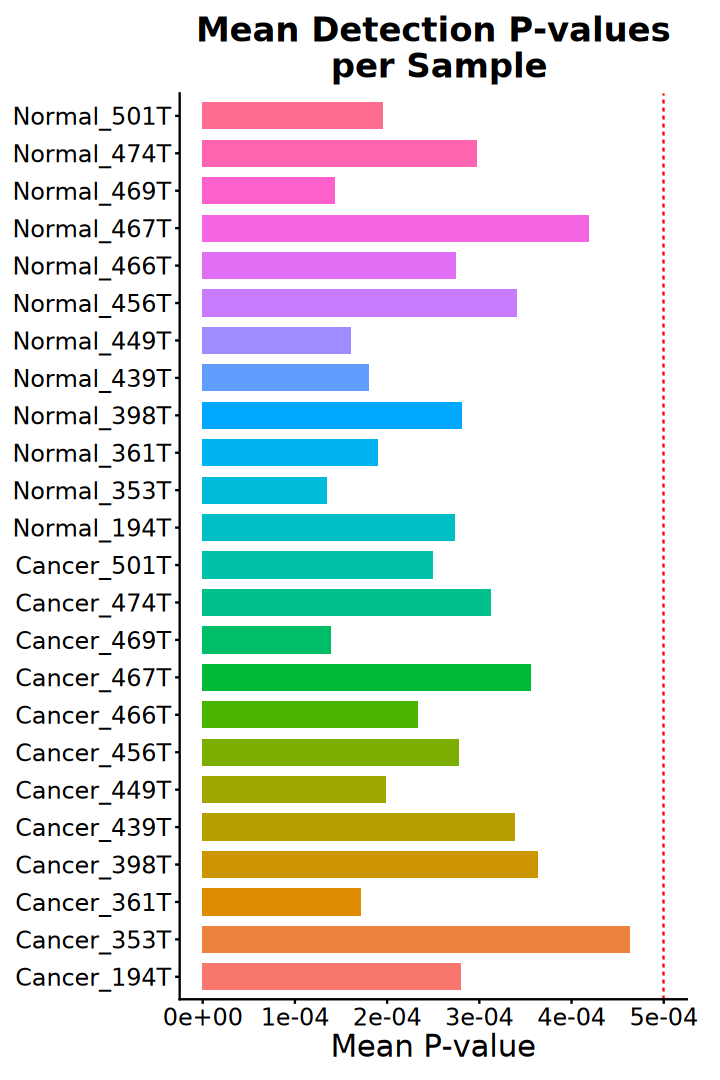

In [13]:
options(repr.plot.width = 6, repr.plot.height = 9)

data.frame(
    Sample = colnames(detP), 
    MeanDetP = colMeans(detP)) |>
    arrange(MeanDetP) |>
    ggplot(aes(x = Sample, y = MeanDetP)) +
        geom_bar(aes(fill = Sample), stat = "identity", width = 0.7) +
        geom_hline(yintercept = 5e-04, linetype = "dashed", color = "red") +
        scale_y_continuous(labels = scales::label_scientific()) +
        coord_flip() +
        labs(title = "Mean Detection P-values\n per Sample",
            x = NULL, y = "Mean P-value") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = margin(t = 10, r = 20, b = 10, l = 10),
            legend.position = "none",
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 14), 
            panel.grid.major = element_blank())

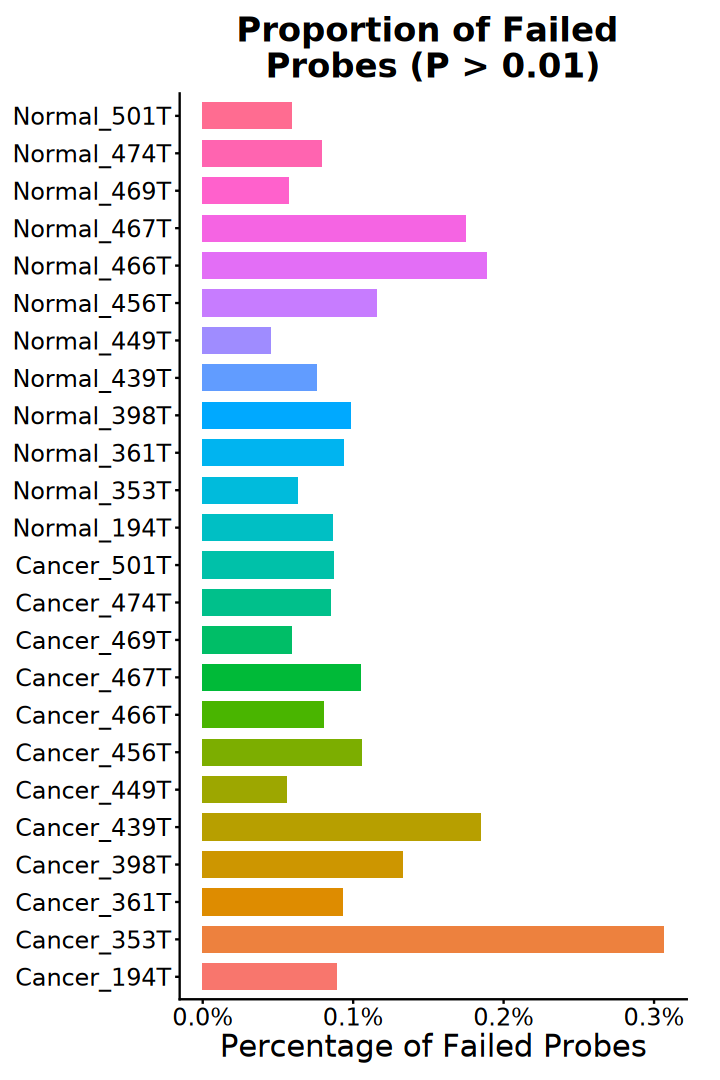

In [14]:
options(repr.plot.width = 6, repr.plot.height = 9)

data.frame(
    Sample = colnames(detP), 
    FailureRate = colSums(detP > 0.01) / nrow(detP)) |>
    arrange(FailureRate) |>
    ggplot(aes(x = Sample, y = FailureRate)) +
        geom_bar(aes(fill = Sample), stat = "identity", width = 0.7) +
        scale_y_continuous(labels = scales::percent) +
        coord_flip() +
        labs(title = "Proportion of Failed \nProbes (P > 0.01)",
            x = NULL, y = "Percentage of Failed Probes") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = margin(t = 10, r = 20, b = 10, l = 10),
            legend.position = "none",
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 14), 
            panel.grid.major = element_blank())

### minfi QC Report

In [15]:
qcReport(
    rgSet = rgSet, sampNames = sampleNames(rgSet), 
    sampGroups = rgSet$Sample_Group,
    pdf = file.path(data_dir, "QCReport_minfi.pdf")) |>
    suppressWarnings()

agg_record_1819437e0ca2 
                      2

### Visualization

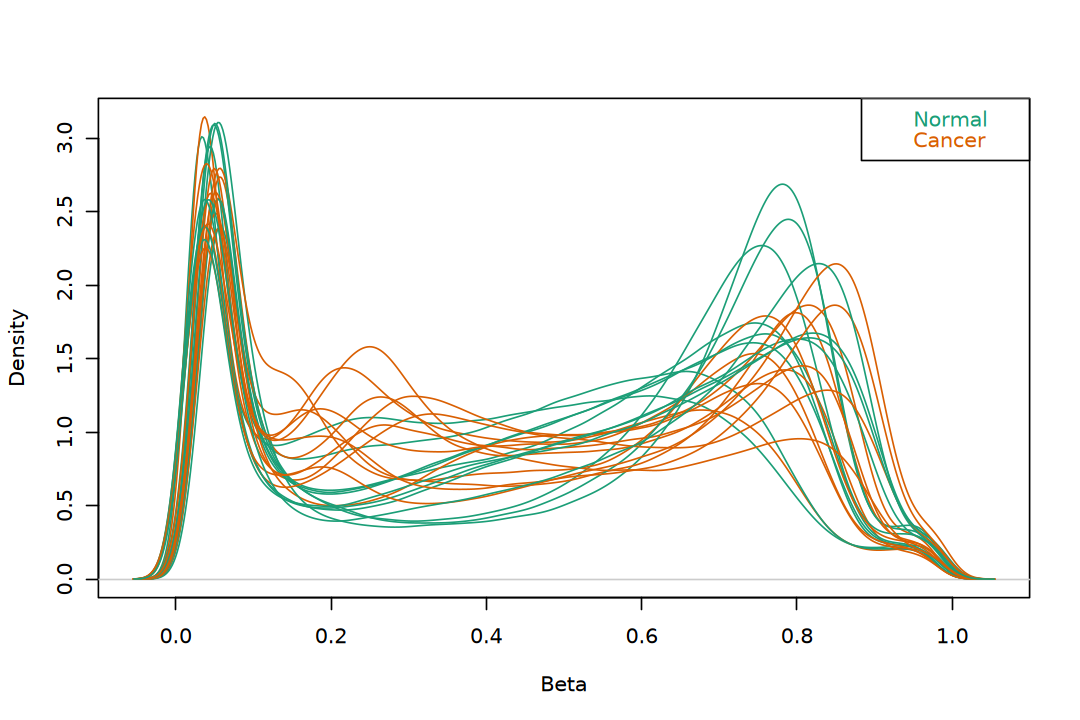

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

densityPlot(dat = rgSet, sampGroups = rgSet$Sample_Group)

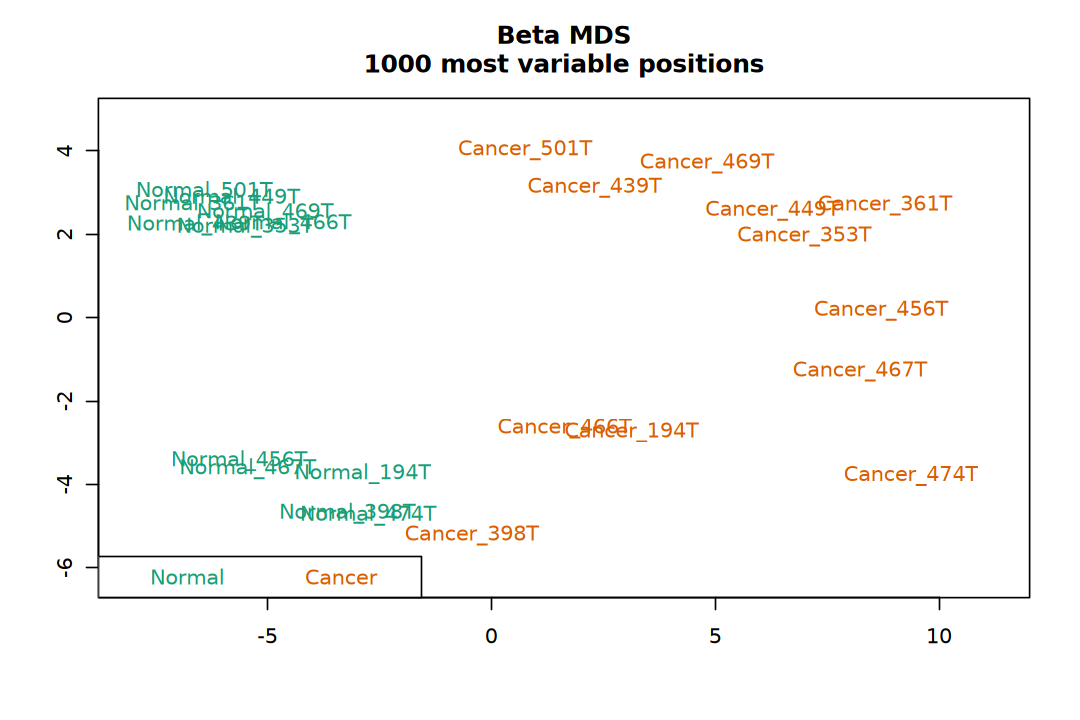

In [17]:
options(repr.plot.width = 9, repr.plot.height = 6)

mdsPlot(
    dat = rgSet, sampNames = sampleNames(rgSet), 
    sampGroups = rgSet$Sample_Group)

### minfiQC

In [18]:
# Converts the Red/Green channel into methylation signal
methySet <- preprocessRaw(rgSet)
methySet

class: MethylSet 
dim: 866091 24 
metadata(0):
assays(2): Meth Unmeth
rownames(866091): cg18478105 cg09835024 ... cg10633746 cg12623625
rowData names(0):
colnames(24): Normal_194T Cancer_194T ... Cancer_467T Normal_467T
colData names(8): Sample_Name Sample_Group ... Slide filenames
Annotation
  array: IlluminaHumanMethylationEPIC
  annotation: ilm10b4.hg19
Preprocessing
  Method: Raw (no normalization or bg correction)
  minfi version: 1.56.0
  Manifest version: 0.3.0

In [19]:
methySet <- minfiQC(methySet, fixOutliers = TRUE, verbose = FALSE)

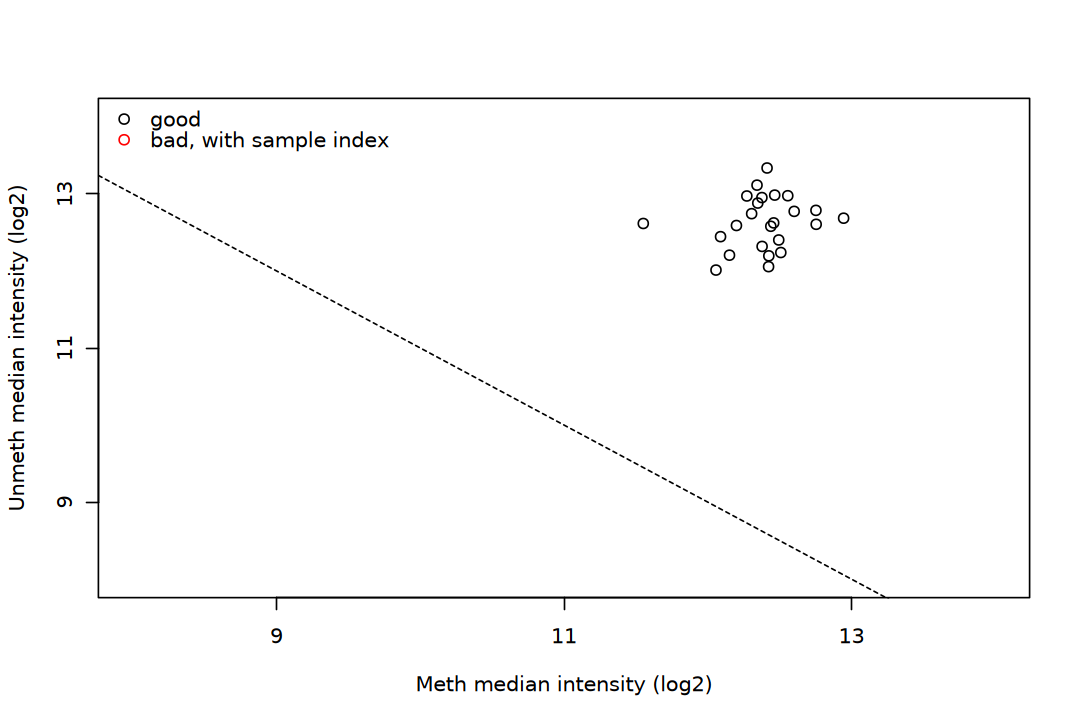

In [20]:
options(repr.plot.width = 9, repr.plot.height = 6)
plotQC(methySet$qc)

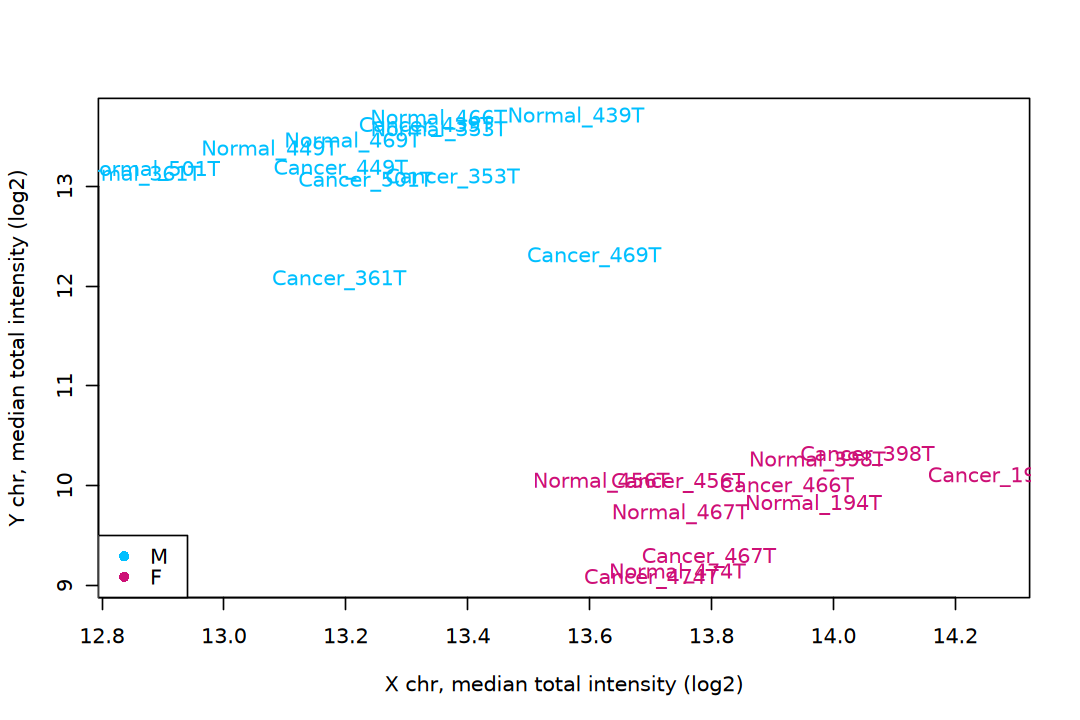

In [22]:
options(repr.plot.width = 9, repr.plot.height = 6)
plotSex(methySet$object, id = sampleNames(methySet))

## 3). Normalization

> - `preprocessFunnorm` function is most appropriate for datasets with global methylation differences such as cancer/normal or vastly different tissue types.
>   - Fortin, JP., Labbe, A., Lemire, M. et al. Functional normalization of 450k methylation array data improves replication in large cancer studies. Genome Biol 15, 503 (2014). https://doi.org/10.1186/s13059-014-0503-2

In [23]:
methySet <- preprocessFunnorm(rgSet = rgSet, verbose = FALSE)
methySet

[preprocessFunnorm] Background correction with noob



class: GenomicRatioSet 
dim: 865859 24 
metadata(0):
assays(2): Beta CN
rownames(865859): cg14817997 cg26928153 ... cg07587934 cg16855331
rowData names(0):
colnames(24): Normal_194T Cancer_194T ... Cancer_467T Normal_467T
colData names(11): Sample_Name Sample_Group ... yMed predictedSex
Annotation
  array: IlluminaHumanMethylationEPIC
  annotation: ilm10b4.hg19
Preprocessing
  Method: NA
  minfi version: NA
  Manifest version: NA

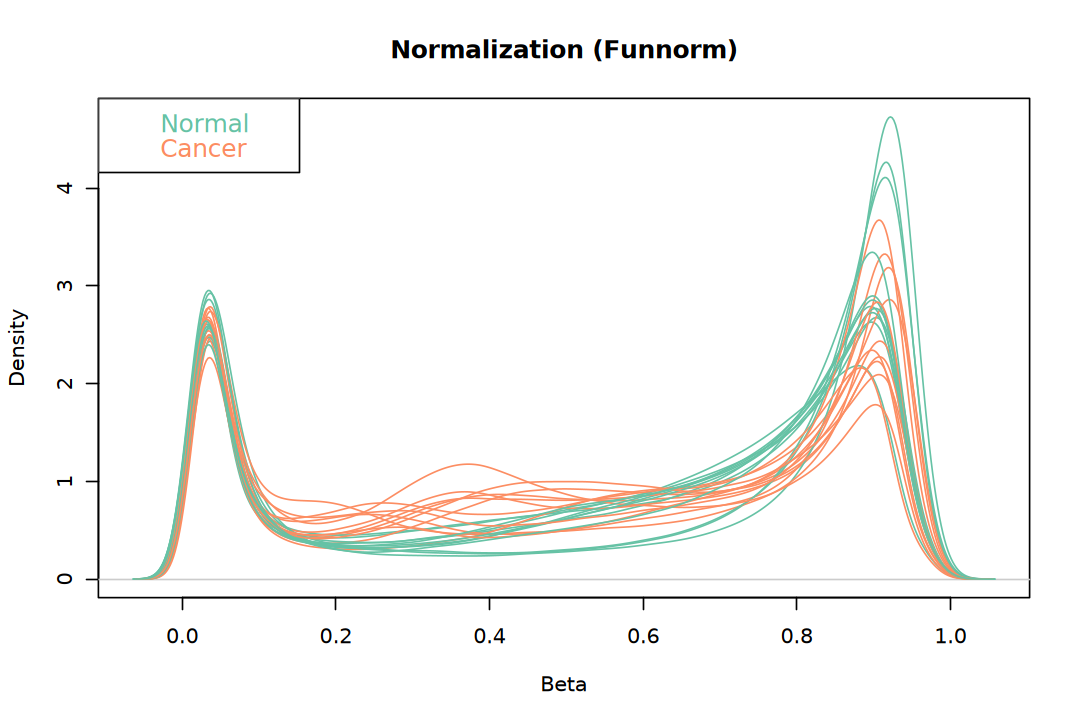

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)
densityPlot(
    dat = getBeta(methySet), 
    sampGroups = methySet$Sample_Group,
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main = "Normalization (Funnorm)")
legend("topleft", legend = levels(methySet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white")

## 4). Filtering Probes

In [25]:
# remove any probes that have failed in one or more samples
detP <- detP[match(featureNames(methySet), rownames(detP)), ] 
keep <- rowSums(detP < 0.01) == ncol(methySet)
methySet_filtered <- methySet[keep, ]

In [26]:
# Calculate statistics
total_probes <- length(keep)
retained_probes <- sum(keep)
filtered_probes <- total_probes - retained_probes
filter_percentage <- (filtered_probes / total_probes) * 100

# Print summary
message("--- Probe Filtering Summary (Detection P-value > 0.01) ---")
message("Total probes starting:    ", total_probes)
message("Probes filtered out:      ", filtered_probes, " (", round(filter_percentage, 2), "%)")
message("Probes retained:          ", retained_probes)
message("---------------------------------------------------------")

--- Probe Filtering Summary (Detection P-value > 0.01) ---

Total probes starting:    865859

Probes filtered out:      7176 (0.83%)

Probes retained:          858683

---------------------------------------------------------



In [27]:
array_anno <- getAnnotation(IlluminaHumanMethylationEPICanno.ilm10b4.hg19)

In [28]:
# remove probes on the sex chromosomes
keep <- !(featureNames(methySet_filtered) %in% 
    array_anno$Name[array_anno$chr %in% c("chrX", "chrY")])
methySet_filtered <- methySet_filtered[keep, ]

In [29]:
# Calculate statistics
total_probes <- length(keep)
retained_probes <- sum(keep)
filtered_probes <- total_probes - retained_probes
filter_percentage <- (filtered_probes / total_probes) * 100

# Print summary
message("--- Probe Filtering Summary (Probes on sex chromosomes) ---")
message("Total probes starting:    ", total_probes)
message("Probes filtered out:      ", filtered_probes, " (", round(filter_percentage, 2), "%)")
message("Probes retained:          ", retained_probes)
message("---------------------------------------------------------")

--- Probe Filtering Summary (Probes on sex chromosomes) ---

Total probes starting:    858683

Probes filtered out:      18882 (2.2%)

Probes retained:          839801

---------------------------------------------------------



In [30]:
# remove probes with SNPs at CpG site
methySet_filtered <- dropLociWithSnps(
    methySet_filtered, snps = c("CpG", "SBE"), maf = 0)

In [31]:
# Print summary
message("--- Probe Filtering Summary (Probes affected by SNP) ---")
message("Probes retained:          ", nrow(methySet_filtered))
message("---------------------------------------------------------")

--- Probe Filtering Summary (Probes affected by SNP) ---

Probes retained:          811152

---------------------------------------------------------



In [32]:
# # exclude cross reactive probes
# reactiveProbes <- read.csv(
#     file = "~/reference/Database/Others/EPIC_cross_reactive_probes.txt", stringsAsFactors = FALSE)

# keep <- !(featureNames(methySet_filtered) %in% reactiveProbes$TargetID)

# methySet_filtered <- methySet_filtered[keep, ]

In [33]:
# # Calculate statistics
# total_probes <- length(keep)
# retained_probes <- sum(keep)
# filtered_probes <- total_probes - retained_probes
# filter_percentage <- (filtered_probes / total_probes) * 100

# # Print summary
# message("--- Probe Filtering Summary (Cross reactive probes) ---")
# message("Total probes starting:    ", total_probes)
# message("Probes filtered out:      ", filtered_probes, " (", round(filter_percentage, 2), "%)")
# message("Probes retained:          ", retained_probes)
# message("---------------------------------------------------------")

## 5). Differentially Analysis

In [34]:
# Extract beta values (proportion of methylation at each CpG site)
# Formula: M / (M + U + 100), where M = methylated intensity, U = unmethylated intensity
# Range: 0–1, where 0 = unmethylated and 1 = fully methylated
# More intuitive and suitable for visualization
bVals <- getBeta(methySet_filtered)

# Extract M values (log2 ratio of methylated vs unmethylated intensities)
# Formula: log2(M/U)
# Range: (-Inf, +Inf), approximately homoscedastic
# Statistically more appropriate for differential methylation analysis
mVals <- getM(methySet_filtered)

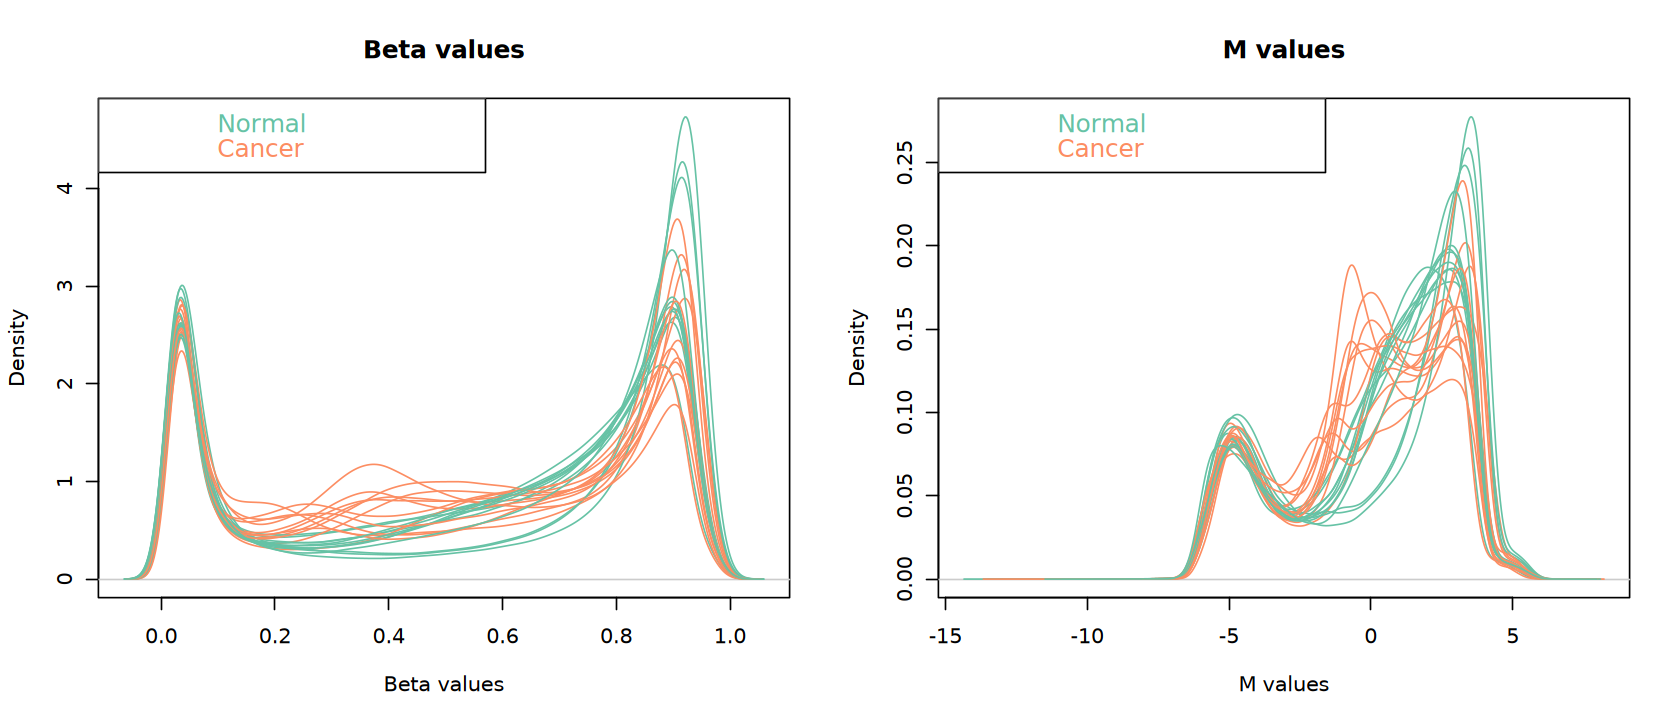

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

par(mfrow = c(1, 2))
densityPlot(
    bVals, sampGroups = methySet$Sample_Group, 
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main="Beta values", xlab="Beta values")
legend("topleft", legend = levels(methySet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

densityPlot(
    mVals, sampGroups = methySet$Sample_Group, 
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main="M values", xlab="M values")
legend("topleft", legend = levels(methySet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

In [36]:
p_cutoff <- 0.01
logFC_cutoff <- 5

### DMPs

In [37]:
dmp_results <- dmpFinder(
    getM(methySet_filtered), pheno = methySet_filtered$Sample_Group, 
    type = "categorical", qCutoff = p_cutoff, shrinkVar = FALSE)

In [38]:
head(dmp_results)

,intercept,f,pval,qval
,<dbl>,<dbl>,<dbl>,<dbl>
cg22497741,-0.4806002,593.9376,2.064291e-17,6.804792e-12
cg14642259,-1.4724297,565.5684,3.470459e-17,6.804792e-12
cg17301223,1.6975365,519.8895,8.465723e-17,1.106625e-11
cg10526659,0.1409909,480.9182,1.926914e-16,1.776430e-11
cg22697045,-0.3920550,470.2344,2.441398e-16,1.776430e-11
cg15385562,0.3059796,455.7850,3.390421e-16,1.776430e-11


### DMPs (limma)

In [ ]:
design <- model.matrix(
     ~ Sample_Group, data = pData(methySet_filtered))

In [40]:
fit <- lmFit(mVals, design)
fit <- eBayes(fit)
dmps <- topTable(fit, coef = 2, number = Inf)

In [41]:
p_cutoff <- 0.01
logFC_cutoff <- with(dmps, mean(abs(logFC)) + 2*sd(abs(logFC)))

print(paste("p-value cutoff:", p_cutoff))
print(paste("logFC cutoff:", logFC_cutoff))

[1] "p-value cutoff: 0.01"
[1] "logFC cutoff: 2.1841216763779"


In [42]:
array_anno_sub <- array_anno[
    match(rownames(mVals), array_anno$Name), 
    c(1:4, 18:19, 22, 24)]

In [43]:
dmps_result <- topTable(
    fit, coef = 2, number = Inf, genelist = array_anno_sub) |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            pvalue < p_cutoff & logFC >  logFC_cutoff ~ "Up",
            pvalue < p_cutoff & logFC < -logFC_cutoff ~ "Down",
            TRUE ~ "NotSig") |> 
            factor(levels = c("Up", "Down", "NotSig")))

In [44]:
head(dmps_result)
table(dmps_result$result)

,chr,pos,strand,Name,Islands_Name,Relation_to_Island,UCSC_RefGene_Name,UCSC_RefGene_Group,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
cg22497741,chr1,1475644,-,cg22497741,chr1:1476093-1476669,N_Shore,C1orf70,Body,4.890220,-2.925710,24.01026,1.204190e-18,4.990227e-13,31.24145,Up
cg14642259,chr11,47359017,+,cg14642259,chr11:47359953-47360216,N_Shore,MYBPC3,Body,-5.866865,1.461003,-23.98849,1.230405e-18,4.990227e-13,31.22385,Down
cg17301223,chr8,145106438,-,cg17301223,chr8:145103285-145108027,Island,OPLAH,Body,5.840042,-1.222484,23.07821,3.077579e-18,8.321281e-13,30.46883,Up
cg10526659,chr2,182322058,+,cg10526659,chr2:182321761-182323029,Island,ITGA4;ITGA4,5'UTR;1stExon,5.431425,-2.574722,22.12876,8.300556e-18,1.683253e-12,29.63910,Up
cg16601494,chr1,1475737,-,cg16601494,chr1:1476093-1476669,N_Shore,C1orf70;C1orf70,5'UTR;1stExon,6.115432,-1.613797,21.70152,1.313762e-17,1.885618e-12,29.25084,Up
cg15385562,chr15,48938239,+,cg15385562,chr15:48936810-48938577,Island,FBN1,TSS1500,5.579726,-2.483883,21.64639,1.394770e-17,1.885618e-12,29.20006,Up



    Up   Down NotSig 
 14870  28566 767716 

### DMRs

In [ ]:
design <- model.matrix(
     ~ Sample_Group, data = pData(methySet_filtered))

In [46]:
dmr_result <- bumphunter(
    methySet_filtered, design, coef = 2, type = "M", 
    cutoff = 0.1, nullMethod = "permutation")

[bumphunterEngine] Using a single core (backend: doSEQ, version: 1.5.2).

[bumphunterEngine] Computing coefficients.

[bumphunterEngine] Finding regions.

[bumphunterEngine] Found 435768 bumps.



In [47]:
head(dmr_result$table)

,chr,start,end,value,area,cluster,indexStart,indexEnd,L,clusterL
,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>
109445,chr6,133561368,133562776,3.247475,123.40403,345529,305495,305532,38,38
18318,chr10,118030848,118034357,3.389515,111.85398,56742,456349,456381,33,33
13705,chr10,7450112,7454759,4.007557,108.20403,41277,428206,428232,27,27
105247,chr6,29520527,29521803,2.842778,99.49723,333827,276342,276376,35,35
48775,chr16,51183988,51186266,3.055832,97.78664,150690,649422,649453,32,36
96458,chr4,154709378,154714287,1.989696,97.49511,302242,216433,216481,49,49


### DMRs (DMRcate)

In [48]:
design <- model.matrix( ~ Sample_Group, data = pData(methySet_filtered))

In [49]:
cpg_anno <- cpg.annotate(
    object = mVals, datatype = "array", what = "M", arraytype = "EPICv1",
    annotation = c(
        array = "IlluminaHumanMethylationEPICanno", 
        annotation = "ilm10b4.hg19"),
    analysis.type = "differential", design = design, coef = 2)

cpg_anno

Your contrast returned 249369 individually significant probes. We recommend the default setting of pcutoff in dmrcate().



CpGannotated object describing 811152 CpG sites, with independent
CpG threshold indexed at fdr=0.05 and 249369 significant CpG sites.

In [50]:
dmrs <- dmrcate(cpg_anno, lambda = 1000, C = 2)

Fitting chr1...

Fitting chr2...

Fitting chr3...

Fitting chr4...

Fitting chr5...

Fitting chr6...

Fitting chr7...

Fitting chr8...

Fitting chr9...

Fitting chr10...

Fitting chr11...

Fitting chr12...

Fitting chr13...

Fitting chr14...

Fitting chr15...

Fitting chr16...

Fitting chr17...

Fitting chr18...

Fitting chr19...

Fitting chr20...

Fitting chr21...

Fitting chr22...

Demarcating regions...

Done!



In [51]:
dmrs_result <- extractRanges(dmrs, genome = "hg19")

see ?DMRcatedata and browseVignettes('DMRcatedata') for documentation

loading from cache



In [52]:
dmrs_result

GRanges object with 39837 ranges and 8 metadata columns:
          seqnames              ranges strand |   no.cpgs min_smoothed_fdr
             <Rle>           <IRanges>  <Rle> | <integer>        <numeric>
      [1]     chr7 130129946-130133110      * |        53                0
      [2]     chr6 133561368-133564578      * |        47                0
      [3]    chr10 118030848-118034357      * |        33                0
      [4]    chr10     7450112-7455714      * |        30                0
      [5]     chr6   30077595-30080782      * |        29                0
      ...      ...                 ...    ... .       ...              ...
  [39833]    chr22   33964297-33964309      * |         2      0.000119047
  [39834]     chr4 148405579-148405611      * |         2      0.000119705
  [39835]     chr1   17751920-17751974      * |         2      0.000120143
  [39836]     chr3   75767268-75767308      * |         2      0.000120263
  [39837]     chr5   74319815-74319850     

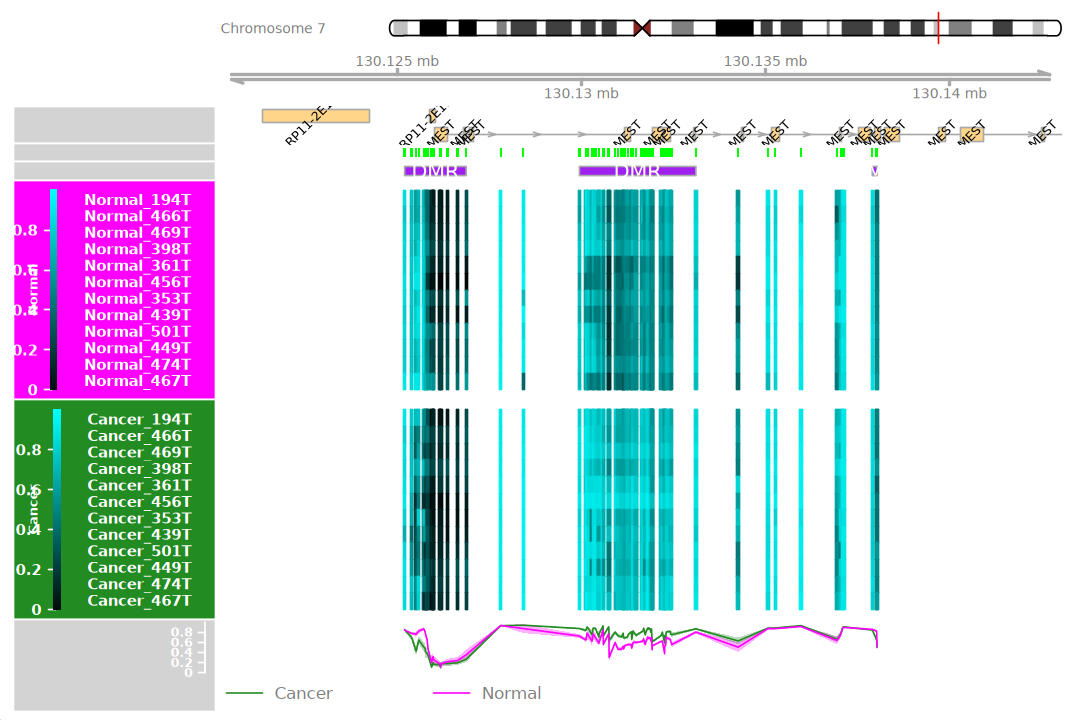

In [53]:
options(repr.plot.width = 9, repr.plot.height = 6)

groups <- c(Normal = "magenta", Cancer = "forestgreen")
cols <- groups[as.character(methySet_filtered$Sample_Group)]

DMR.plot(
    ranges = dmrs_result, dmr = 1, CpGs = cpg_anno, what = "Beta",
    arraytype = "EPICv1", phen.col = cols, genome = "hg19")

### Blocks

In [54]:
design <- model.matrix( ~ Sample_Group, data = pData(methySet_filtered))

In [55]:
methySet_collapse <- cpgCollapse(methySet_filtered, what = "M")

[cpgCollapse] Creating annotation.


[cpgCollapseAnnotation] Clustering islands and clusters of probes.


[cpgCollapseAnnotation] Computing new annotation.


[cpgCollapseAnnotation] Defining blocks.


[cpgCollapse] Collapsing data



.........
.............


In [56]:
block_result <- blockFinder(
    methySet_collapse$object, design, coef = 2, what = "M",
    cutoff = 0.1, nullMethod = "permutation")

[bumphunterEngine] Using a single core (backend: doSEQ, version: 1.5.2).

[bumphunterEngine] Computing coefficients.

[bumphunterEngine] Smoothing coefficients.

Loading required package: rngtools

[bumphunterEngine] Finding regions.

[bumphunterEngine] Found 1751 bumps.



In [57]:
head(block_result$table)

,chr,start,end,value,area,cluster,indexStart,indexEnd,L,clusterL
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>
1708,chr20,47841452,62214615,-0.8776128,2158.928,143,402031,405554,2460,3821
592,chr2,210994670,223230064,-1.0038369,1412.399,15,68555,70379,1407,6651
1279,chr11,124751257,134945750,-0.8832580,1361.101,106,269062,270980,1541,5077
412,chr1,70840727,91265989,-0.8103803,1225.295,3,17149,18975,1512,12118
781,chr5,12322,9069719,-0.9370708,1079.506,35,120625,122497,1152,4363
1073,chr8,131401452,140953459,-1.0029171,1039.022,63,208592,209714,1036,4781


# 4. ChAMP

> - Yuan Tian, Tiffany J Morris, Amy P Webster, Zhen Yang, Stephan Beck, Andrew Feber, Andrew E Teschendorff, ChAMP: updated methylation analysis pipeline for Illumina BeadChips, Bioinformatics, Volume 33, Issue 24, December 2017, Pages 3982–3984, https://doi.org/10.1093/bioinformatics/btx513.

In [58]:
suppressPackageStartupMessages(library(ChAMP))
suppressPackageStartupMessages(library(ChAMPdata))

No methods found in package 'RSQLite' for request: 'dbListFields' when loading 'lumi'

Warning message:
"replacing previous import 'plyr::mutate' by 'plotly::mutate' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::rename' by 'plotly::rename' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::arrange' by 'plotly::arrange' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::summarise' by 'plotly::summarise' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plotly::subplot' by 'Hmisc::subplot' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::summarize' by 'Hmisc::summarize' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::is.discrete' by 'Hmisc::is.discrete' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plotly::last_plot' by 'ggplot2::last_plot' when loading 'ChAMP'"
Warning message:
"replacing previous import 'globaltest::model.matrix' 

## 1). Data Import and Filtering

> 1. Filter out probes with a p-value greater than 0.01
> 2. Filter out probes with fewer than 3 beads per probe in at least 5% of samples
> 3. Filter out all non-CpG probes
> 4. Filter out all SNP-related probes
> 5. Filter out all multiple-hit probes
> 6. Filter out all probes located on the X and Y chromosomes

In [59]:
myLoad <- champ.load(
    file.path(data_dir, "idat"), method = "minfi", 
    force = TRUE, arraytype = "EPIC")
# myImport <- champ.import(
#     directory = file.path(data_dir, "idat"), 
#     arraytype = "EPIC")
# myFilter <-champ.filter(
#     beta = myImport$beta, pd = myImport$pd, 
#     arraytype = "EPIC")

[===========================]

[<<<< ChAMP.LOAD START >>>>>]

-----------------------------


[ Loading Data with Minfi Method ]



----------------------------------

Loading data from ~/dataset_1/methylation_dataset/array/GSE149282/idat

[read.metharray.sheet] Found the following CSV files:



[1] "/home/fugui/dataset_1/methylation_dataset/array/GSE149282/idat/SampleSheet.csv"


<< Read DataSet Success. >>


The fraction of failed positions per sample
 
            (You may need to delete samples with high proportion of failed probes
): 



           Failed CpG Fraction.
GSM4495491         0.0008601867
GSM4495492         0.0008878975
GSM4495493         0.0018889470
GSM4495494         0.0008001469
GSM4495495         0.0005715335
GSM4495496         0.0005911619
GSM4495497         0.0009814211
GSM4495498         0.0013266504
GSM4495499         0.0009329274
GSM4495500         0.0009306181
GSM4495501         0.0011557677
GSM4495502         0.0010564710
GSM4495503         0.0006269549
GSM4495504         0.0030643431
GSM4495505         0.0007562716
GSM4495506         0.0018485355
GSM4495507         0.0008705783
GSM4495508         0.0005923165
GSM4495509         0.0005565235
GSM4495510         0.0004502991
GSM4495511         0.0008509498
GSM4495512         0.0007920646
GSM4495513         0.0010472341
GSM4495514         0.0017446204


Filtering probes with a detection p-value above 0.01 in one or more samples has removed 7195 probes from the analysis. If a large number of probes have been removed, ChAMP suggests you to identify potentially bad samples.

<< Filter DetP Done. >>



There is no NA values in your matrix, there is no need to imputation.


Filtering probes with a beadcount <3 in at least 5% of samples, has removed 4832 from the analysis.

<< Filter Beads Done. >>


Filtering non-cg probes, has removed 2894 from the analysis.

<< Filter NoCG Done. >>


Using general EPIC SNP list for filtering.

Filtering probes with SNPs as identified in Zhou's Nucleic Acids Research Paper, 2016, has removed 96223 from the analysis.

<< Filter SNP Done. >>


Filtering probes that align to multiple locations as identified in Nordlund et al, has removed 15 from the analysis.

<< Filter MultiHit Done. >>


Filtering probes on the X or Y chromosome has removed 16463 from the analysis.

<< Filter XY chromosome Done. >>


[Beta

In [60]:
names(myLoad)

[1] "mset"      "rgSet"     "pd"        "intensity" "beta"      "detP"

In [61]:
# Generate interactive plot for summary information of a list of CpGs
CpG.GUI(CpG = rownames(myLoad$beta), arraytype = "EPIC")

Loading required package: shiny


Attaching package: 'shiny'


The following objects are masked from 'package:DT':

    dataTableOutput, renderDataTable



Listening on http://127.0.0.1:7989



## 2). Data Exploration

[===========================]

[<<<<< ChAMP.QC START >>>>>>]



-----------------------------

champ.QC Results will be saved in ~/dataset_1/methylation_dataset/array/GSE149282/ChAMP_QC

[QC plots will be proceed with 738469 probes and 24 samples.]


<< Prepare Data Over. >>

<< plot mdsPlot Done. >>




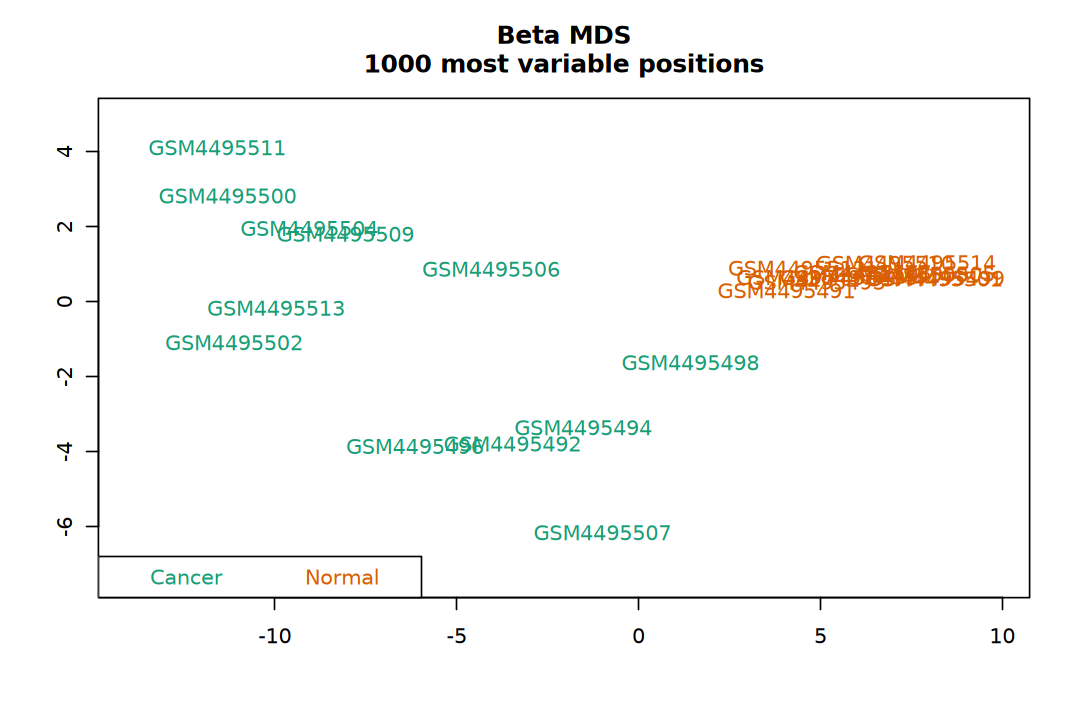

<< Plot densityPlot Done. >>


< Dendrogram Plot Feature Selection Method >: No Selection, directly use all CpGs to calculate distance matrix.



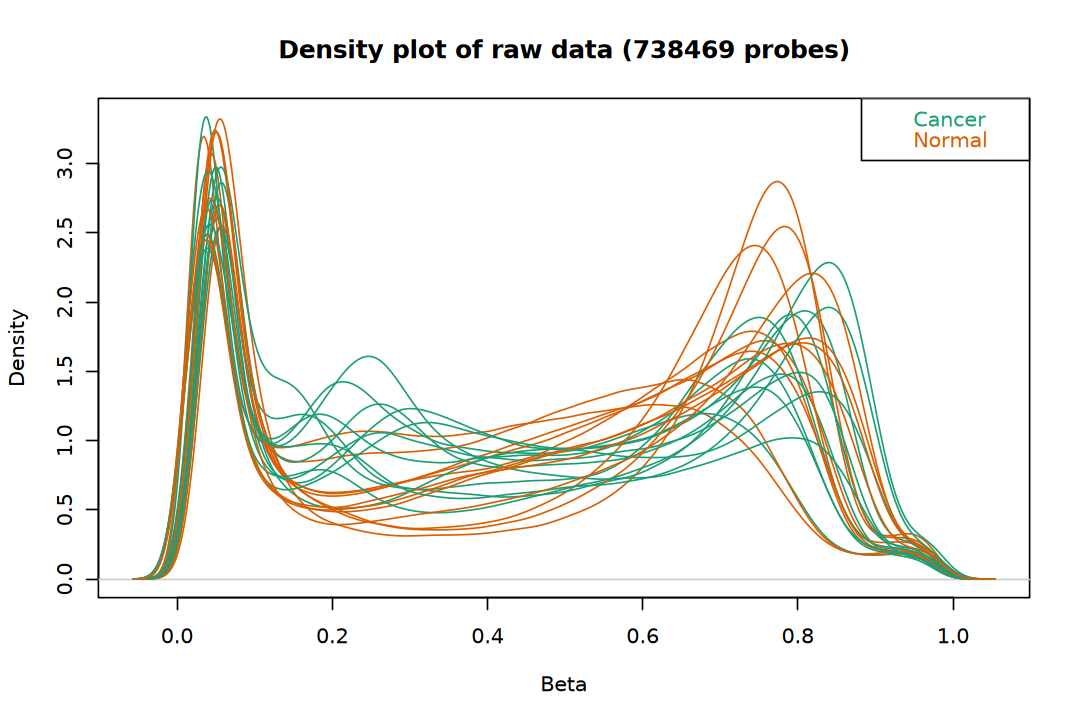

<< Plot dendrogram Done. >>


[<<<<<< ChAMP.QC END >>>>>>>]

[===========================]

[You may want to process champ.norm() next.]




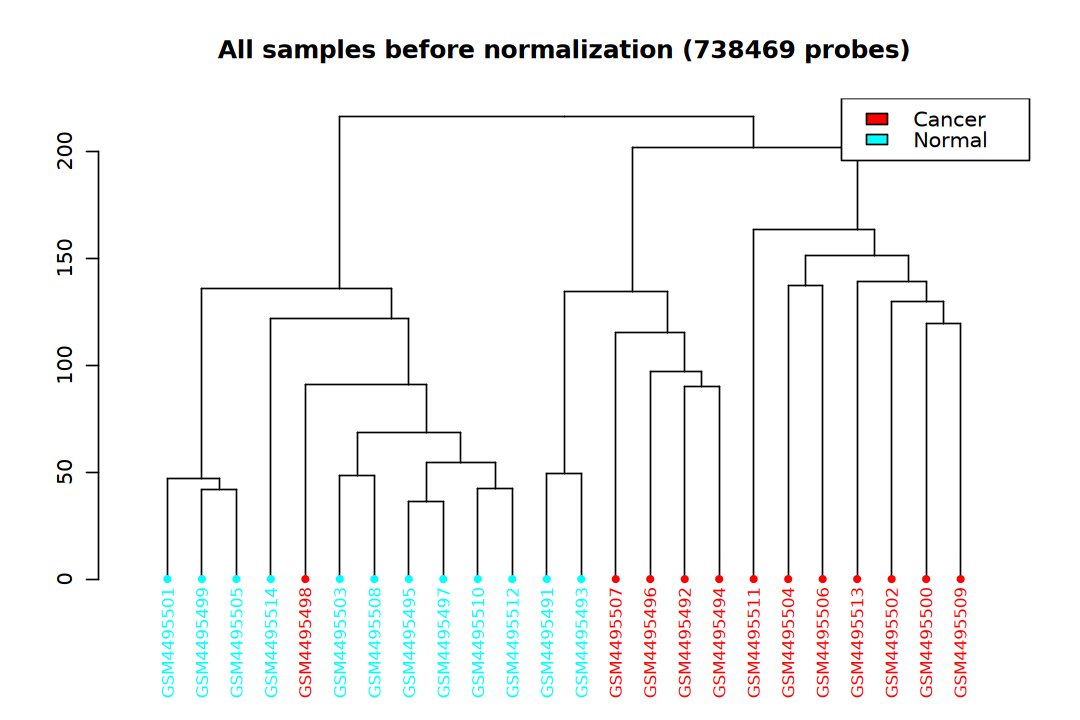

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)
champ.QC(
    beta = myLoad$beta, 
    pheno = myLoad$pd$Sample_Group, 
    resultsDir = file.path(data_dir, "ChAMP_QC"))

In [63]:
QC.GUI(beta = myLoad$beta, pheno = myLoad$pd$Sample_Group, arraytype = "EPIC")


Listening on http://127.0.0.1:7989



## 3). Normalization

In [64]:
# Normalization of methylation data, with options for BMIQ, PBC, FunctionalNormalization, and SWAN methods.
champ.norm <- function (beta = myLoad$beta, rgSet = myLoad$rgSet, mset = myLoad$mset, 
    resultsDir = "./CHAMP_Normalization/", method = "BMIQ", plotBMIQ = FALSE, 
    arraytype = "450K", cores = 3) 
{
    message("[===========================]")
    message("[>>>>> ChAMP.NORM START <<<<<<]")
    message("-----------------------------")
    if (!file.exists(resultsDir)) 
        dir.create(resultsDir)
    message("champ.norm Results will be saved in ", resultsDir)
    message("[ SWAN method call for BOTH rgSet and mset input, FunctionalNormalization call for rgset only , while PBC and BMIQ only needs beta value. Please set parameter correctly. ]\n")
    if (method == "SWAN") {
        beta.p = getBeta(preprocessSWAN(rgSet, mset), "Illumina")
    }
    else if (method == "BMIQ") {
        message("<< Normalizing data with BMIQ Method >>")
        message("Note that,BMIQ function may fail for bad quality samples (Samples did not even show beta distribution).")
        if (arraytype == "EPIC") 
            data(probeInfoALL.epic.lv)
        else data(probeInfoALL.lv)
        design.v <- as.numeric(lapply(probeInfoALL.lv, function(x) x)$Design[match(rownames(beta), 
            probeInfoALL.lv$probeID)])
        if (min(beta, na.rm = TRUE) == 0) {
            beta[beta == 0] <- 1e-06
            message("Zeros in your dataset have been replaced with 0.000001\n")
        }
        current_cwd <- getwd()
        if (plotBMIQ) 
            setwd(resultsDir)
        if (cores > 1) {
            if (cores > detectCores()) 
                cores <- detectCores()
            message(cores, " cores will be used to do parallel BMIQ computing.")
            cl <- makeCluster(cores)
            registerDoParallel(cl)
            beta.p <- foreach(x = 1:ncol(beta), .combine = cbind, 
                .export = c("champ.BMIQ", "blc")) %dopar% champ.BMIQ(beta[, 
                x], design.v, sampleID = colnames(beta)[x], plots = plotBMIQ)$nbeta
            stopCluster(cl)
        }
        else {
            beta.p <- sapply(1:ncol(beta), function(x) champ.BMIQ(beta[, 
                x], design.v, sampleID = colnames(beta)[x], plots = plotBMIQ)$nbeta)
        }
        setwd(current_cwd)
    }
    else if (method == "PBC") {
        message("<< Normalizing data with PBC Method >>")
        if (arraytype == "EPIC") 
            data(probeInfoALL.epic.lv)
        else data(probeInfoALL.lv)
        design.v <- as.numeric(lapply(probeInfoALL.lv, function(x) x)$Design[match(rownames(beta), 
            probeInfoALL.lv$probeID)])
        if (min(beta, na.rm = TRUE) == 0) {
            beta[beta == 0] <- 1e-06
            message("Zeros in your dataset have been replaced with 0.000001\n")
        }
        beta.p = DoPBC(beta, design.v)
    }
    else if (method == "FunctionalNormalization") {
        if (is.null(rgSet)) 
            stop("rgSet not found, it is required for FunctionalNormalization")
        if (arraytype == "EPIC") 
            rgSet@annotation[2] <- "ilm10b4.hg19"
        beta_fun <- getBeta(preprocessFunnorm(rgSet))
        beta.p <- matrix(
            NA_real_, nrow = nrow(beta), ncol = ncol(beta),
            dimnames = list(rownames(beta), colnames(beta)))
        common <- intersect(rownames(beta), rownames(beta_fun))
        beta.p[common, ] <- beta_fun[common, colnames(beta), drop = FALSE]
        # beta.p <- getBeta(preprocessFunnorm(rgSet))[rownames(beta), ]
    }
    else {
        stop("Please Select Normalization Method from: BMIQ,PBC, FunctionalNormalization and SWAN.")
    }
    rownames(beta.p) <- rownames(beta)
    colnames(beta.p) <- colnames(beta)
    message("[>>>>> ChAMP.NORM END <<<<<<]")
    message("[===========================]")
    message("[You may want to process champ.SVD() next.]\n")
    return(beta.p)
}

In [65]:
myNorm <- champ.norm(
    rgSet = myLoad$rgSet, 
    method = "FunctionalNormalization", arraytype = "EPIC", 
    resultsDir = file.path(data_dir, "ChAMP_Normalization"))

[===========================]

[>>>>> ChAMP.NORM START <<<<<<]

-----------------------------

champ.norm Results will be saved in ~/dataset_1/methylation_dataset/array/GSE149282/ChAMP_Normalization

[ SWAN method call for BOTH rgSet and mset input, FunctionalNormalization call for rgset only , while PBC and BMIQ only needs beta value. Please set parameter correctly. ]


[preprocessFunnorm] Background and dye bias correction with noob

[preprocessFunnorm] Mapping to genome

[preprocessFunnorm] Quantile extraction

[preprocessFunnorm] Normalization

[>>>>> ChAMP.NORM END <<<<<<]

[===========================]

[You may want to process champ.SVD() next.]




In [66]:
# Conduct imputation on beta matrix contains missing value.
myImpute <- champ.impute(beta = myNorm, pd = myLoad$pd)

[===========================]

[<<< ChAMP.IMPUTE START >>>>]

-----------------------------

<method>:Combine. (Suitable for Large Data Set)

(1): 0 Samples contain 0.1 or above NA will be removed.

(2): 204 Probes contain 0.2 or above NA will be removed.



Cluster size 738265 broken into 257415 480850 
Cluster size 257415 broken into 93251 164164 
Cluster size 93251 broken into 45829 47422 
Cluster size 45829 broken into 24777 21052 
Cluster size 24777 broken into 12164 12613 
Cluster size 12164 broken into 4322 7842 
Cluster size 4322 broken into 1841 2481 
Cluster size 1841 broken into 883 958 
Done cluster 883 
Done cluster 958 
Done cluster 1841 
Cluster size 2481 broken into 1475 1006 
Done cluster 1475 
Done cluster 1006 
Done cluster 2481 
Done cluster 4322 
Cluster size 7842 broken into 3439 4403 
Cluster size 3439 broken into 1800 1639 
Cluster size 1800 broken into 748 1052 
Done cluster 748 
Done cluster 1052 
Done cluster 1800 
Cluster size 1639 broken into 1090 549 
Done cluster 1090 
Done cluster 549 
Done cluster 1639 
Done cluster 3439 
Cluster size 4403 broken into 1782 2621 
Cluster size 1782 broken into 958 824 
Done cluster 958 
Done cluster 824 
Done cluster 1782 
Cluster size 2621 broken into 1362 1259 
Done cluster

(3): The rest NA are imputed by KNN method which parameter k as 5.

[<<<<< ChAMP.IMPUTE END >>>>]

[===========================]



In [67]:
myNorm <- myNorm[rowSums(is.na(myNorm)) == 0, ]

[===========================]

[<<<<< ChAMP.SVD START >>>>>]

-----------------------------

champ.SVD Results will be saved in ~/dataset_1/methylation_dataset/array/GSE149282/ChAMP_SVD .


Your beta parameter is data.frame format. ChAMP is now changing it to matrix.

[SVD analysis will be proceed with 738265 probes and 24 samples.]



[ champ.SVD() will only check the dimensions between data and pd, instead if checking if Sample_Names are correctly matched (because some user may have no Sample_Names in their pd file),thus please make sure your pd file is in accord with your data sets (beta) and (rgSet).]


<< Following Factors in your pd(sample_sheet.csv) will be analysised: >>

<Sample_Group>(character):Normal, Cancer

<Sample_Pair>(character):194T, 466T, 469T, 398T, 361T, 456T, 353T, 439T, 501T, 449T, 474T, 467T

<Sample_Gender>(character):Female, Male

<Array>(character):R01C01, R02C01, R03C01, R04C01, R05C01, R06C01, R07C01, R08C01

<Slide>(character):200811050117, 200811050116, 2

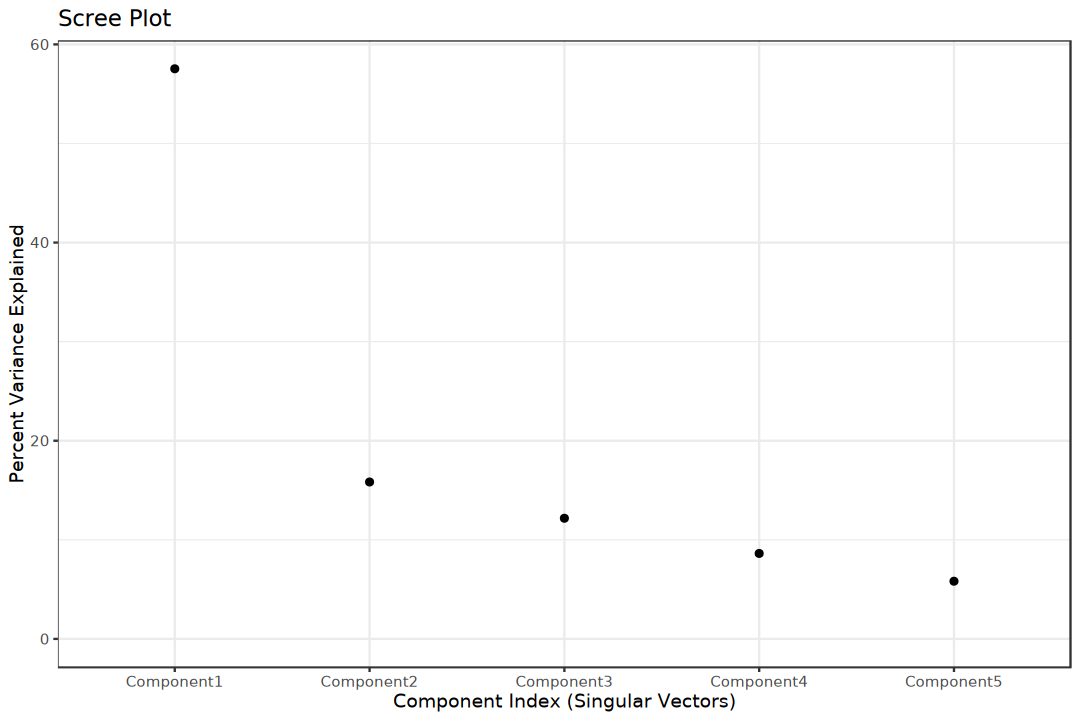

<< Plot SVD matrix successfully. >>

[<<<<<< ChAMP.SVD END >>>>>>]

[===========================]

[If the batch effect is not significant, you may want to process champ.DMP() or champ.DMR() or champ.BlockFinder() next, otherwise, you may want to run champ.runCombat() to eliminat batch effect, then rerun champ.SVD() to check corrected result.]




Sample_Group,Sample_Pair,Sample_Gender,Array,Slide
0.0000678457,0.9998118,0.81736133,0.8982304,0.96078944
0.0646716875,0.7572687,0.60333177,0.3152891,0.13669543
0.6861059570,0.1317496,0.86249023,0.9806499,0.03473526
0.4189234409,0.2571107,0.06467169,0.5759781,0.03166637
0.4189234409,0.2907191,0.86249023,0.9444996,0.01887343


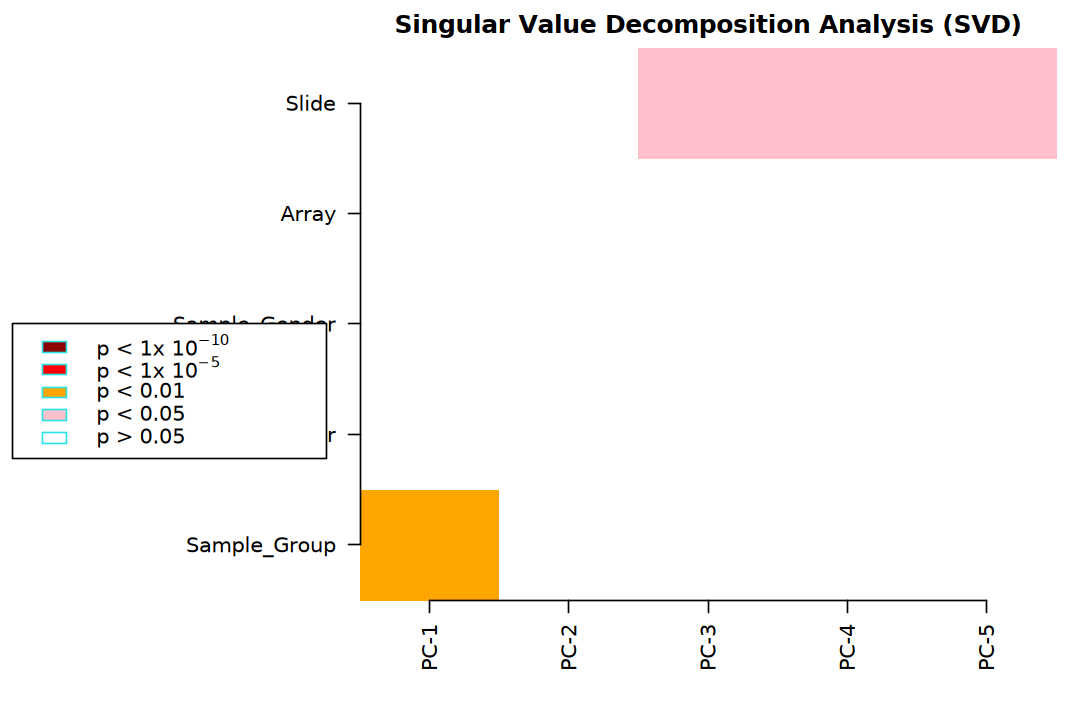

In [68]:
champ.SVD(
    beta = as.data.frame(myNorm), pd = myLoad$pd, 
    resultsDir = file.path(data_dir, "ChAMP_SVD"))
# champ.SVD(
#     beta = as.data.frame(myImpute$beta), rgSet = myLoad$rgSet, pd = myLoad$pd, 
#     RGEffect = TRUE, resultsDir = file.path(data_dir, "ChAMP_SVD"))

## 5). Differentially Analysis

### DMPs (limma)

In [69]:
myDMP <- champ.DMP(
    beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    arraytype = "EPIC")

[===========================]

[<<<<< ChAMP.DMP START >>>>>]

-----------------------------

!!! Important !!! New Modification has been made on champ.DMP(): 


    (1): In this version champ.DMP() if your pheno parameter contains more than two groups of phenotypes, champ.DMP() would do pairewise differential methylated analysis between each pair of them. But you can also specify compare.group to only do comparasion between any two of them.


    (2): champ.DMP() now support numeric as pheno, and will do linear regression on them. So covariates like age could be inputted in this function. You need to make sure your inputted "pheno" parameter is "numeric" type.


--------------------------------


[ Section 1:  Check Input Pheno Start ]


  You pheno is character type.



    Your pheno information contains following groups. >>

    <Normal>:12 samples.

    <Cancer>:12 samples.

    [The power of statistics analysis on groups contain very few samples may not strong.]

    pheno contains only 2 phenotypes

    compare.group parameter is NULL, two pheno types will be added into Compare List.

    Normal_to_Cancer compare group : Normal, Cancer


[ Section 1:  Check Input Pheno Done ]



[ Section 2:  Find Differential Methylated CpGs Start ]


  -----------------------------

  Start to Compare : Normal, Cancer

  Contrast Matrix



         Contrasts
Levels    pNormal-pCancer
  pCancer              -1
  pNormal               1


  You have found 221074 significant MVPs with a BH adjusted P-value below 0.05.

  Calculate DMP for Normal and Cancer done.


[ Section 2:  Find Numeric Vector Related CpGs Done ]



[ Section 3:  Match Annotation Start ]



[ Section 3:  Match Annotation Done ]


[<<<<<< ChAMP.DMP END >>>>>>]

[===========================]

[You may want to process DMP.GUI() or champ.GSEA() next.]




In [70]:
myDMP[[1]] |> head()

,logFC,AveExpr,t,P.Value,adj.P.Val,B,Normal_AVG,Cancer_AVG,deltaBeta,CHR,MAPINFO,Strand,Type,gene,feature,cgi,feat.cgi,UCSC_Islands_Name,SNP_ID,SNP_DISTANCE
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<int>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
cg16601494,-0.6811555,0.3855784,-32.63761,8.499554e-21,6.274924e-15,35.14755,0.04500061,0.7261561,0.6811555,1,1475737,R,I,C1orf70,5'UTR,shore,5'UTR-shore,chr1:1476093-1476669,rs561063770,23
cg09296001,-0.6211071,0.3584904,-29.08221,1.141413e-19,3.585612e-14,33.20254,0.04793688,0.6690440,0.6211071,7,127672564,R,I,SND1,Body,island,Body-island,chr7:127671158-127672853,,
cg17301223,-0.6963844,0.4034374,-28.76769,1.457043e-19,3.585612e-14,33.01353,0.05524519,0.7516296,0.6963844,8,145106438,R,I,OPLAH,Body,island,Body-island,chr8:145103285-145108027,rs566592895;rs148937107,51;47
cg26256223,-0.6427665,0.4001910,-27.66938,3.487716e-19,6.437148e-14,32.32954,0.07880769,0.7215742,0.6427665,8,145106582,R,II,OPLAH,Body,island,Body-island,chr8:145103285-145108027,rs553503071,20
cg03241244,-0.6259463,0.3517517,-27.16245,5.276233e-19,7.790517e-14,32.00073,0.03877861,0.6647249,0.6259463,12,122017052,F,I,KDM2B,Body,island,Body-island,chr12:122016170-122017693,rs112471261;rs531357599,21;33
cg22697045,0.4346937,0.6504315,25.73476,1.762573e-18,2.168744e-13,31.02714,0.86777833,0.4330846,-0.4346937,11,47359223,F,I,MYBPC3,Body,shore,Body-shore,chr11:47359953-47360216,rs3729950,21


In [71]:
DMP.GUI(DMP = myDMP[[1]], beta = myNorm, pheno = myLoad$pd$Sample_Group)


Listening on http://127.0.0.1:7989



### DMRs (minfi, DMRcate)

In [72]:
# ?DMRcate only supports EPICv2 chips.
myDMR <- champ.DMR(
    beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    method = "Bumphunter", arraytype = "EPIC")

[===========================]

[<<<<< ChAMP.DMR START >>>>>]

-----------------------------

!!! important !!! We just upgrate champ.DMR() function, since now champ.DMP() could works on multiple phenotypes, but ProbeLasso can only works on one DMP result, so if your pheno parameter contains more than 2 phenotypes, and you want to use ProbeLasso function, you MUST specify compare.group=c("A","B"). Bumphunter and DMRcate should not be influenced.


[ Section 1:  Check Input Pheno Start ]


  You pheno is character type.

    Your pheno information contains following groups. >>

    <Normal>:12 samples.

    <Cancer>:12 samples.


[ Section 1:  Check Input Pheno Done ]



[ Section 2:  Run DMR Algorithm Start ]


<< Find DMR with Bumphunter Method >>

3 cores will be used to do parallel Bumphunter computing.

According to your data set, champ.DMR() detected 11257 clusters contains MORE THAN 7 probes within300 maxGap. These clusters will be used to find DMR.


[bumphunterEngine] Paralleliz

In [73]:
myDMP[[1]] |> head()

,logFC,AveExpr,t,P.Value,adj.P.Val,B,Normal_AVG,Cancer_AVG,deltaBeta,CHR,MAPINFO,Strand,Type,gene,feature,cgi,feat.cgi,UCSC_Islands_Name,SNP_ID,SNP_DISTANCE
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<int>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
cg16601494,-0.6811555,0.3855784,-32.63761,8.499554e-21,6.274924e-15,35.14755,0.04500061,0.7261561,0.6811555,1,1475737,R,I,C1orf70,5'UTR,shore,5'UTR-shore,chr1:1476093-1476669,rs561063770,23
cg09296001,-0.6211071,0.3584904,-29.08221,1.141413e-19,3.585612e-14,33.20254,0.04793688,0.6690440,0.6211071,7,127672564,R,I,SND1,Body,island,Body-island,chr7:127671158-127672853,,
cg17301223,-0.6963844,0.4034374,-28.76769,1.457043e-19,3.585612e-14,33.01353,0.05524519,0.7516296,0.6963844,8,145106438,R,I,OPLAH,Body,island,Body-island,chr8:145103285-145108027,rs566592895;rs148937107,51;47
cg26256223,-0.6427665,0.4001910,-27.66938,3.487716e-19,6.437148e-14,32.32954,0.07880769,0.7215742,0.6427665,8,145106582,R,II,OPLAH,Body,island,Body-island,chr8:145103285-145108027,rs553503071,20
cg03241244,-0.6259463,0.3517517,-27.16245,5.276233e-19,7.790517e-14,32.00073,0.03877861,0.6647249,0.6259463,12,122017052,F,I,KDM2B,Body,island,Body-island,chr12:122016170-122017693,rs112471261;rs531357599,21;33
cg22697045,0.4346937,0.6504315,25.73476,1.762573e-18,2.168744e-13,31.02714,0.86777833,0.4330846,-0.4346937,11,47359223,F,I,MYBPC3,Body,shore,Body-shore,chr11:47359953-47360216,rs3729950,21


In [74]:
DMR.GUI(
    DMR = myDMR, beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    runDMP = TRUE, arraytype = "EPIC")

!!! important !!! Since we just upgrated champ.DMP() function, which is now can support multiple phenotypes. Here in DMR.GUI() function, if you want to use "runDMP" parameter, and your pheno contains more than two groups of phenotypes, you MUST specify compare.group parameter as compare.group=c("A","B") to get DMP value between group A and group B.


[ Section 1: Calculate DMP Start  ]


  You pheno is character type.

    Your pheno information contains following groups. >>

    <Normal>:12 samples.

    <Cancer>:12 samples.

  Your pheno contains EXACTLY two phenotypes, which is good, compare.group is not needed.

Calculating DMP



[===========================]

[<<<<< ChAMP.DMP START >>>>>]

-----------------------------

!!! Important !!! New Modification has been made on champ.DMP(): 


    (1): In this version champ.DMP() if your pheno parameter contains more than two groups of phenotypes, champ.DMP() would do pairewise differential methylated analysis between each pair of them. But you can also specify compare.group to only do comparasion between any two of them.


    (2): champ.DMP() now support numeric as pheno, and will do linear regression on them. So covariates like age could be inputted in this function. You need to make sure your inputted "pheno" parameter is "numeric" type.


--------------------------------


[ Section 1:  Check Input Pheno Start ]


  You pheno is character type.

    Your pheno information contains following groups. >>

    <Normal>:12 samples.

    <Cancer>:12 samples.

    [The power of statistics analysis on groups contain very few samples may not strong.]

    pheno contains 

         Contrasts
Levels    pNormal-pCancer
  pCancer              -1
  pNormal               1


  You have found 738265 significant MVPs with a BH adjusted P-value below 1.

  Calculate DMP for Normal and Cancer done.


[ Section 2:  Find Numeric Vector Related CpGs Done ]



[ Section 3:  Match Annotation Start ]



[ Section 3:  Match Annotation Done ]


[<<<<<< ChAMP.DMP END >>>>>>]

[===========================]

[You may want to process DMP.GUI() or champ.GSEA() next.]



[ Section 1: Calculate DMP Done  ]



[ Section 2: Mapping DMR to annotation Start  ]


  Generating Annotation File

  Generating Annotation File Success


[ Section 2: Mapping DMR to annotation Done  ]



Listening on http://127.0.0.1:7989



### Blocks

In [75]:
myBlock <- champ.Block(
    beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    arraytype = "EPIC", core = 4)

[===========================]

[<<<< ChAMP.Block START >>>>]

-----------------------------

<< Load Annotation Successfully >>

<< Get Clusters by cgi-info Successfully >>

<< Calculate Average Beta Value Successfully >>

<< Generate Block Position Successfully >>

<< New Clusters are generated for blocks >>

<< Generate information for New Clusters >>

[bumphunterEngine] Parallelizing using 4 workers/cores (backend: doParallelMC, version: 1.0.17).

[bumphunterEngine] Computing coefficients.

[bumphunterEngine] Smoothing coefficients.

[bumphunterEngine] Performing 500 permutations.

[bumphunterEngine] Computing marginal permutation p-values.

[bumphunterEngine] Smoothing permutation coefficients.

[bumphunterEngine] cutoff: 0.027

[bumphunterEngine] Finding regions.

[bumphunterEngine] Found 985 bumps.

[bumphunterEngine] Computing regions for each permutation.

[bumphunterEngine] Estimating p-values and FWER.

<< Run Bumphunter Successfully >>

[<<<<< ChAMP.BLOCK END >>>>>]

[======

In [76]:
myBlock[[1]] |> head()

,chr,start,end,value,area,cluster,indexStart,indexEnd,L,clusterL,p.value,fwer,p.valueArea,fwerArea
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Block_1,13,19478976,41130000,0.1210836,277.4026,169,74391,76681,2291,3937,0,0,0.000000e+00,0.000
Block_2,20,49378294,62913080,0.1297130,264.4848,217,168455,170493,2039,3581,0,0,2.332492e-06,0.002
Block_3,5,100682581,126300209,0.1093325,211.7771,74,221758,223694,1937,8726,0,0,9.329968e-06,0.008
Block_4,11,118452474,128354757,0.1175104,194.1272,161,56613,58264,1652,4782,0,0,9.329968e-06,0.008
Block_5,13,100066368,113797982,0.1193475,185.3467,174,80634,82186,1553,2669,0,0,2.099243e-05,0.010
Block_6,2,177116896,191142262,0.1410083,153.4171,36,154925,156012,1088,1385,0,0,4.198486e-05,0.016


In [77]:
Block.GUI(
    Block = myBlock, beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    runDMP = TRUE, compare.group = NULL, arraytype="EPIC")

!!! important !!! Since we just upgrated champ.DMP() function, which is now can support multiple phenotypes. Here in Block.GUI() function, if you want to use "runDMP" parameter, and your pheno contains more than two groups of phenotypes, you MUST specify compare.group parameter as compare.group=c("A","B") to get DMP value between group A and group B.



Generation CpG information

  You pheno is character type.

    Your pheno information contains following groups. >>

    <Normal>:12 samples.

    <Cancer>:12 samples.

  Your pheno contains EXACTLY two phenotypes, which is good, compare.group is not needed.

Calculating DMP

[===========================]

[<<<<< ChAMP.DMP START >>>>>]

-----------------------------

!!! Important !!! New Modification has been made on champ.DMP(): 


    (1): In this version champ.DMP() if your pheno parameter contains more than two groups of phenotypes, champ.DMP() would do pairewise differential methylated analysis between each pair of them. But you can also specify compare.group to only do comparasion between any two of them.


    (2): champ.DMP() now support numeric as pheno, and will do linear regression on them. So covariates like age could be inputted in this function. You need to make sure your inputted "pheno" parameter is "numeric" type.


--------------------------------


[ Section 1:  Ch

         Contrasts
Levels    pNormal-pCancer
  pCancer              -1
  pNormal               1


  You have found 738265 significant MVPs with a BH adjusted P-value below 1.

  Calculate DMP for Normal and Cancer done.


[ Section 2:  Find Numeric Vector Related CpGs Done ]



[ Section 3:  Match Annotation Start ]



[ Section 3:  Match Annotation Done ]


[<<<<<< ChAMP.DMP END >>>>>>]

[===========================]

[You may want to process DMP.GUI() or champ.GSEA() next.]



Listening on http://127.0.0.1:7989



---

# Reference

> 1. [Bioconductor workflow: methylationArrayAnalysis](https://www.bioconductor.org/packages/release/workflows/html/methylationArrayAnalysis.html)
> 2. [ChAMP: The Chip Analysis Methylation Pipeline](https://bioconductor.org/packages/release/bioc/vignettes/ChAMP/inst/doc/ChAMP.html)